In [62]:
import os
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import URL, create_engine, text
from statsmodels.stats.proportion import proportions_ztest

pio.templates.default = 'plotly_dark'
pio.renderers.default = 'notebook'
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.3f}'.format)

current_dir = Path.cwd().resolve()

ROOT = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "notebooks" / "nba_analysis.ipynb").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Project root was not found. Run the notebook from within the repository."
    )

notebooks_dir = str(ROOT / "notebooks")

if notebooks_dir not in sys.path:
    sys.path.insert(0, notebooks_dir)

import nba_top_players

load_dotenv(ROOT / ".env")

DB_PATH = ROOT / "database" / "data" / "nba_star.db"

if not DB_PATH.is_file():
    raise FileNotFoundError(f"Database file was not found: {DB_PATH}")

In [63]:
engine = create_engine(
    URL.create("sqlite", database=str(DB_PATH))
)

with engine.connect() as connection:
    integrity_result = connection.execute(
        text("PRAGMA integrity_check")
    ).scalars().all()

    table_names = connection.execute(
        text(
            "SELECT name FROM sqlite_master "
            "WHERE type = 'table' ORDER BY name"
        )
    ).scalars().all()

if integrity_result != ["ok"]:
    raise RuntimeError(f"Database integrity check failed: {integrity_result}")

required_tables = {
    "fact_player_stats",
    "dim_player",
    "dim_season",
    "dim_team_scope",
    "dim_player_context",
    "dim_phase",
}

missing_tables = required_tables - set(table_names)

if missing_tables:
    raise RuntimeError(f"Required tables are missing: {sorted(missing_tables)}")

print(f"Database: {DB_PATH}")
print("Integrity check: OK")
print(f"Tables: {len(table_names)}")

Database: G:\بوت کمپ تحلیل داده\New folder\github\nba-data-analysis\database\data\nba_star.db
Integrity check: OK
Tables: 9


In [64]:
df_dim_player = pd.read_sql('SELECT * from dim_player',engine)


In [65]:
df_dim_player_context = pd.read_sql('SELECT * from dim_player_context',engine)


In [66]:
df_fact_player_salary = pd.read_sql('SELECT * from fact_player_salary',engine)
df_fact_player_salary = df_fact_player_salary[df_fact_player_salary['season_key'] != 1]
df_fact_player_salary['season_key']= df_fact_player_salary['season_key'] - 1


In [77]:
df_fact_player_stats = pd.read_sql('SELECT * from fact_player_stats',engine)
df_fact_player_stats = df_fact_player_stats[df_fact_player_stats["is_player_phase_total"] == 1]
df_fact_player_stats = df_fact_player_stats.dropna()
df_fact_player_stats['field_goal_percentage'] = df_fact_player_stats['field_goals']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['2P_Rate'] = df_fact_player_stats['two_point_attempts']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['2P%'] = df_fact_player_stats['two_point_field_goals']/df_fact_player_stats['two_point_attempts']
df_fact_player_stats['3P_Rate'] = df_fact_player_stats['three_point_attempts']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['3P%'] = df_fact_player_stats['three_point_field_goals']/df_fact_player_stats['three_point_attempts']
df_fact_player_stats['free_throws_percentage'] = df_fact_player_stats['free_throws']/df_fact_player_stats['free_throw_attempts']
df_fact_player_stats['awards_source_num'] = (df_fact_player_stats['awards_source_text'].str.strip() != '').astype(int)
df_fact_player_stats.fillna(0,inplace = True)


,stat_key,source_stat_id,player_key,season_key,scope_key,phase_key,context_key,totals_source_rank,advanced_source_rank,is_player_phase_total,...,defensive_box_plus_minus,box_plus_minus,value_over_replacement_player,field_goal_percentage,2P_Rate,2P%,3P_Rate,3P%,free_throws_percentage,awards_source_num
0,1,1,6,1,12,2,58,127,138,1,...,1.400,1.600,0.100,0.571,0.571,0.667,0.429,0.444,0.600,0
1,2,2,9,1,21,2,153,183,169,1,...,1.400,-1.700,0.000,0.143,0.286,0.000,0.714,0.200,0.500,0
2,3,3,16,1,23,2,433,130,112,1,...,0.400,-1.300,0.000,0.480,0.840,0.571,0.160,0.000,0.571,0
3,4,4,18,1,23,2,255,115,126,1,...,-2.700,-3.500,0.000,0.327,0.673,0.394,0.327,0.188,0.778,0
4,5,5,22,1,14,2,118,44,19,1,...,1.900,-0.500,0.200,0.425,0.460,0.596,0.540,0.279,0.800,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4681,4682,4682,957,5,4,1,260,225,291,1,...,-0.700,0.100,0.500,0.452,0.551,0.536,0.449,0.349,0.854,0
4682,4683,4683,959,5,15,1,147,462,448,1,...,0.300,-5.900,-0.200,0.315,0.685,0.324,0.315,0.294,0.750,0
4683,4684,4684,960,5,8,1,67,351,343,1,...,0.100,-3.700,-0.200,0.463,0.846,0.500,0.154,0.261,0.677,0
4684,4685,4685,962,5,15,1,44,246,256,1,...,-0.400,-4.500,-0.600,0.397,0.500,0.487,0.500,0.307,0.827,0


In [78]:
result_1 = pd.merge(
    df_fact_player_stats,
    df_fact_player_salary,
    on = ['player_key','season_key'],
    how = 'inner'
)
print(len(result_1))
result_2 = pd.merge(
    result_1,
    df_dim_player,
    on = 'player_key',
    how = 'inner'
)
print(len(result_2))


2564
2564


In [ ]:
result2_sorted =  result_2.sort_values(by = ['player_key','season_key'])
all_data_train =  result2_sorted[result2_sorted['season_key'] != 4]
all_data_test = result2_sorted[result2_sorted['season_key'] == 4]
# pd.set_option('display.max_rows', None)
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [76]:
X_train = all_data_train.iloc[:,[7,8,11,13,14,20,22,23,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48
                                ,49,50,51,52,53,54,60,61]]
X_test = all_data_test.iloc[:,[7,8,11,13,14,20,22,23,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48
                                ,49,50,51,52,53,54,60,61]]
y_train = all_data_train.iloc[:,[56]]
y_test = all_data_test.iloc[:,[56]]
X
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [71]:
uni = result2_sorted['awards_source_text'].unique()

print(result2_sorted['awards_source_text'].value_counts().to_dict())

{'': 2349, 'AS': 36, 'ASNBA3': 7, '6MOY-9': 5, '6MOY-4': 5, 'ROY-2': 4, '6MOY-7': 4, '6MOY-6': 4, '6MOY-11': 4, 'ROY-3': 4, '6MOY-2': 4, 'ROY-6': 4, 'Finals MVP-1': 4, 'ROY-1': 4, '6MOY-1': 4, 'DPOY-9': 3, 'DPOY-4DEF2': 3, '6MOY-3': 3, 'ROY-4': 3, '6MOY-8': 3, 'ROY-5': 3, 'MVP-10ASNBA2': 3, 'DEF2': 3, '6MOY-5': 3, 'DPOY-5ASDEF2': 2, 'MIP-1AS': 2, 'DPOY-2DEF1': 2, 'MVP-7ASNBA2': 2, 'MVP-8ASNBA2': 2, 'MVP-4ASNBA1': 2, 'DPOY-3DEF1': 2, '6MOY-10': 2, 'DPOY-11': 2, 'MVP-3ASNBA1': 2, 'MVP-6ASNBA1': 2, 'DPOY-11DEF2': 2, '6MOY-12': 2, 'MVP-1ASNBA1': 2, 'DPOY-7DEF2': 2, 'DPOY-11DEF1': 1, 'DPOY-8': 1, 'MVP-6DPOY-2ASNBA1DEF1': 1, 'DPOY-4ASNBA3DEF1': 1, 'MVP-12DPOY-2ASDEF1': 1, 'ROY-46MOY-8': 1, 'DPOY-10DEF2': 1, 'MVP-5ASNBA2': 1, 'MVP-9ASNBA3': 1, 'DPOY-6': 1, 'CPOY-10ASNBA3': 1, 'MVP-11CPOY-1ASNBA3': 1, 'CPOY-3AS': 1, 'MVP-96MOY-3': 1, 'MVP-7ASNBA3': 1, 'MVP-6CPOY-6ASNBA2': 1, 'DPOY-10ASDEF2': 1, '6MOY-15': 1, 'MVP-1DPOY-1ASNBA1DEF1': 1, 'MVP-4DPOY-5ASNBA1DEF1': 1, 'MVP-3DPOY-6ASNBA1DEF1': 1, 'M

In [72]:
df = pd.read_sql('SELECT distinct fact_player_salary.player_key,fact_player_salary.annual_salary_usd, dim_player.listed_height_inches FROM dim_player INNER JOIN fact_player_salary ON fact_player_salary.player_key = dim_player.player_key where season_key = 4',engine)


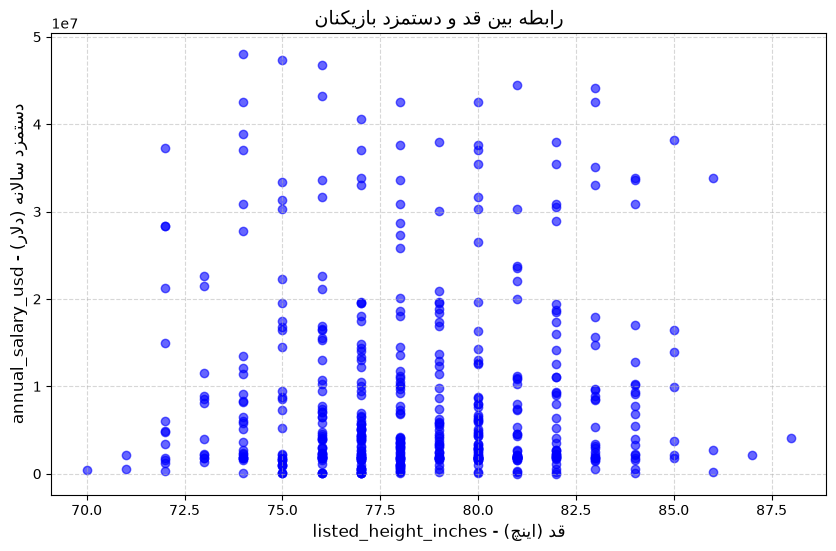

In [73]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df['listed_height_inches'],
    df['annual_salary_usd'],
    alpha=0.6,
    color='blue',
)

# تنظیمات برچسب‌ها و عنوان نمودار
plt.title('رابطه بین قد و دستمزد بازیکنان', fontsize=14)
plt.xlabel('قد (اینچ) - listed_height_inches', fontsize=12)
plt.ylabel('دستمزد سالانه (دلار) - annual_salary_usd', fontsize=12)

# نمایش شبکه (Grid) برای خوانایی بهتر
plt.grid(True, linestyle='--', alpha=0.5)

# نمایش نمودار
plt.show()